# Worked Example: Midterm Project, Films Based on Video Games

**ECON 3916 · a worked example for the midterm, built in class on Wed 4 Nov**

This notebook is the midterm starter, filled in for one small question, so you can see what each
section looks like when it is done. Lay it beside your own notebook: same headings, same order.

It is an example of the *process*, not a model answer to copy. Your question, data and words are your own,
and your project stays **no AI** throughout.

## Start here

1. In Colab, run the cells top to bottom. The cell after Setup downloads the data files from the repository if they are not already here.
2. To download fresh copies from the original sources instead, run `get_data.py` (it rewrites `data/`). Every number in the example report is printed by the last code cell.

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Opened in Colab from GitHub? Then the data/ folder is not here yet: download it from the repository.
import os, urllib.request
REPO_RAW = "https://raw.githubusercontent.com/RyanPiao/econ3916-midterm-example/main/data/"
os.makedirs("data", exist_ok=True)
for name in ["films_wikipedia.csv", "directors_wikidata.csv", "cpi_fred.csv", "games_wikipedia.csv",
             "second_search.csv", "fx_usd_per_gbp_fred.csv"]:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(REPO_RAW + name, f"data/{name}")
print(sorted(os.listdir("data")))

['cpi_fred.csv', 'directors_wikidata.csv', 'films_wikipedia.csv', 'fx_usd_per_gbp_fred.csv', 'games_wikipedia.csv', 'rt_spot_check.csv', 'second_search.csv']


## Data provenance

In [3]:
SOURCE_URL = "https://en.wikipedia.org/wiki/List_of_films_based_on_video_games"   # + Wikidata, FRED CPIAUCSL
DOWNLOAD_DATE = "2026-11-03"
FILE_NAME = "data/films_wikipedia.csv"

**Who collected it, for what purpose, what is missing and why?**

Wikipedia editors compiled the table. Each Rotten Tomatoes score is the share of critics' reviews that are positive,
with the number of reviews counted; each budget and gross cites Box Office Mojo or The Numbers, which collect
studio-reported figures for the trade press. Budgets are studio *claims*: they are rounded, sometimes a range,
and missing for small releases. Scores and grosses are still moving for films released in 2026. Directors' birth dates come from Wikidata; a few directors have no page there.
The CPI is the BLS CPI-U from FRED, used to put every dollar in 2024 prices. When each game came out comes from
Wikipedia too: the film's infobox names the game or series it is based on, and that page gives its first release year.

## Line 1 · Where it comes from: the first read

In [4]:
raw = pd.read_csv(FILE_NAME)
print(raw.shape)
print(raw[["Title", "Director", "Release date", "Budget", "Worldwide box office"]].head(3).to_string())

(68, 12)
               Title                    Director       Release date             Budget Worldwide box office
0  Super Mario Bros.  Rocky MortonAnnabel Jankel       May 28, 1993  $42–48 million[2]       $20,929,518[3]
1      Double Dragon                James Yukich   November 4, 1994    $7.8 million[6]        $2,341,309[7]
2     Street Fighter          Steven E. de Souza  December 23, 1994    $35 million[10]      $99,433,436[11]


## Line 2 · Its shape: what is one row?

In [5]:
films = raw.rename(columns={"Title": "title", "Director": "director", "Release date": "released",
                            "Budget": "budget_text", "Worldwide box office": "gross_text",
                            "Rotten Tomatoes": "rt_text"})
films["year"] = films["released"].str.extract(r"((?:19|20)\d\d)", expand=False).astype(int)

# Is the title a key? Three titles appear twice: remakes.
print("Repeated titles:", films["title"].duplicated().sum())
print(films.loc[films["title"].duplicated(keep=False), ["title", "year"]].sort_values("title").to_string(index=False))
print("Repeated title + year:", films.duplicated(["title", "year"]).sum())

Repeated titles: 3
         title  year
 Mortal Kombat  1995
 Mortal Kombat  2021
 Resident Evil  2002
 Resident Evil  2026
Street Fighter  1994
Street Fighter  2026
Repeated title + year: 0


In [6]:
def to_dollars(text):
    # "$42–48 million[2]" -> 45,000,000; anything not in US dollars (a £ budget, N/A) -> NaN
    if pd.isna(text):
        return np.nan
    s = re.sub(r"\[.*?\]", "", str(text)).replace(",", "").strip()
    if not s.startswith("$"):
        return np.nan
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
    value = np.mean(nums[:2]) if "–" in s else nums[0]
    return value * 1e6 if "million" in s else value * 1e9 if "billion" in s else value

films["budget"] = films["budget_text"].map(to_dollars)
films["gross"] = films["gross_text"].map(to_dollars)
not_usd = films["budget_text"].notna() & films["budget"].isna()
print("Budgets not in US dollars:", films.loc[not_usd, ["title", "budget_text"]].values.tolist())

Budgets not in US dollars: [['Moshi Monsters: The Movie', '£2.3\xa0million[285]']]


In [7]:
# Text to numbers, again: the Rotten Tomatoes column reads "26% (46 reviews)[4]".
films["rt"] = films["rt_text"].str.extract(r"^(\d+)\s*%", expand=False).astype(float)
films["reviews"] = films["rt_text"].str.extract(r"\((\d+) reviews?\)", expand=False).astype(float)
print(films[["rt_text", "rt", "reviews"]].head(3).to_string(index=False))
print("No score:", films.loc[films["rt"].isna(), ["title", "rt_text"]].values.tolist())

             rt_text   rt  reviews
 26% (46 reviews)[4] 26.0     46.0
 12% (17 reviews)[8] 12.0     17.0
17% (63 reviews)[12] 17.0     63.0
No score: [['Far Cry', 'N/A (2 reviews)[76]'], ['Dead Trigger', 'N/A (1 review)[129]'], ['Heavenly Sword', 'N/A (1 review)[289]'], ['Scarygirl', 'N/A (8 reviews)[310]']]


## Line 3 · What is missing

In [8]:
print(films[["rt", "budget", "gross"]].isna().sum().to_string())
print()
print("Missing, by format:")
print(films.groupby("format")[["rt", "budget"]].apply(lambda g: g.isna().sum()).to_string())

rt        4
budget    7
gross     1

Missing, by format:
             rt  budget
format                 
animated      2       6
live-action   2       1


## Line 4 · The one join

In [9]:
directors = pd.read_csv("data/directors_wikidata.csv")
naive = films.merge(directors[["director", "born"]], on="director", how="left", indicator=True)
print(len(films), "films in,", len(naive), "rows out")
print(naive["_merge"].value_counts().to_string())
print("Not matched:", naive.loc[naive["_merge"] == "left_only", "director"].tolist())

68 films in, 68 rows out
_merge
both          58
left_only     10
right_only     0
Not matched: ['Rocky MortonAnnabel Jankel', 'James Yukich', 'Mike Cuff and Scott Windhauser', 'Wip Vernooij', 'Gun Ho Jung', 'Clay KaytisFergal Reilly', 'Takanori Tsujimoto', 'Aaron HorvathMichael Jelenic', 'Ricard Cussó', 'Aaron HorvathMichael Jelenic']


In [10]:
# Co-directors come out of the table glued together ("Rocky MortonAnnabel Jankel"). Key on the first one listed.
known = sorted(directors["director"], key=len, reverse=True)
def first_director(cell):
    return next((k for k in known if cell.startswith(k)), cell.split(" and ")[0])

films["first_director"] = films["director"].map(first_director)
df = films.merge(directors[["director", "born"]].rename(columns={"director": "first_director"}),
                 on="first_director", how="left", indicator=True, validate="many_to_one")
print(df["_merge"].value_counts().to_string())
print("Matched but no birth date on Wikidata:", df.loc[(df["_merge"] == "both") & df["born"].isna(), "first_director"].tolist())

_merge
both          62
left_only      6
right_only     0
Matched but no birth date on Wikidata: ['Dwight Little', 'Jared Hess']


In [11]:
# One unit system: every dollar in 2024 prices, joined on release year (budgets are used in Section 3).
cpi = pd.read_csv("data/cpi_fred.csv", parse_dates=["observation_date"])
cpi = cpi.groupby(cpi["observation_date"].dt.year)["CPIAUCSL"].mean().rename_axis("year").rename("cpi").reset_index()
df = df.drop(columns="_merge").merge(cpi, on="year", how="left", validate="many_to_one")
to_2024 = cpi.set_index("year").loc[2024, "cpi"] / df["cpi"]
df["gross_m"] = df["gross"] * to_2024 / 1e6      # $ millions, 2024 prices
df["budget_m"] = df["budget"] * to_2024 / 1e6
df["dir_age"] = df["year"] - pd.to_numeric(df["born"].str[:4])
df["animated"] = (df["format"] == "animated").astype(int)
print(df[["title", "year", "budget", "budget_m"]].head(3).to_string(index=False))

            title  year     budget  budget_m
Super Mario Bros.  1993 45000000.0 97.708375
    Double Dragon  1994  7800000.0 16.507645
   Street Fighter  1994 35000000.0 74.072767


In [12]:
# The second join: when did the game come out? Keyed on title + year, because three titles were remade.
games = pd.read_csv("data/games_wikipedia.csv")[["title", "year", "source_page", "game_year"]]
df = df.merge(games, on=["title", "year"], how="left", indicator=True, validate="one_to_one")
print(df["_merge"].value_counts().to_string())
print("No game year:", df.loc[df["game_year"].isna(), "title"].tolist())
df = df.drop(columns="_merge")
# X: the director's age when the game first came out (negative = born after it)
df["age_game"] = df["game_year"] - pd.to_numeric(df["born"].str[:4])
print(df[["title", "source_page", "game_year", "dir_age", "age_game"]].head(4).to_string(index=False))

_merge
both          68
left_only      0
right_only     0
No game year: ['Scarygirl', 'The Super Mario Galaxy Movie']
            title       source_page  game_year  dir_age  age_game
Super Mario Bros. Mario (franchise)     1981.0     38.0      26.0
    Double Dragon     Double Dragon     1987.0      NaN       NaN
   Street Fighter Street Fighter II     1991.0     47.0      44.0
    Mortal Kombat     Mortal Kombat     1992.0     30.0      27.0


## Line 3, second pass · Search before you label a gap

Before calling a gap missing, look for the value somewhere else. `data/second_search.csv` records every search, with
its source: what was found, and what was searched for and not found. Some "missing" birth dates were the first
lookup's fault (a redirect, a shared page, a director the table did not link).

In [13]:
born_missing_first = int(df["born"].isna().sum())     # after the first lookup
search = pd.read_csv("data/second_search.csv", dtype={"value": str})
found = search.dropna(subset=["value"])
for _, r in found.iterrows():
    row = (df["title"] == r["title"]) & (df["year"] == r["year"])
    assert row.sum() == 1, r["title"]
    if r["field"] == "born":
        df.loc[row, "born"] = r["value"]
    elif r["field"] == "budget":
        df.loc[row, "budget"] = float(r["value"])
    elif r["field"] == "game_year":
        df.loc[row, "game_year"] = float(r["value"])
print("Found:", len(found)); print(found[["title", "field", "value"]].to_string(index=False))
print("Searched, not found:", search["value"].isna().sum())
print(search.loc[search["value"].isna(), ["title", "field"]].to_string(index=False))
# recompute everything that depends on a filled column
df["dir_age"] = df["year"] - pd.to_numeric(df["born"].str[:4])
df["budget_m"] = df["budget"] * to_2024 / 1e6
df["age_game"] = df["game_year"] - pd.to_numeric(df["born"].str[:4])
print("Birth dates still missing:", df["born"].isna().sum())

Found: 7
                       title     field      value
               Double Dragon      born 1963-03-12
                      Tekken      born 1956-01-13
           A Minecraft Movie      born 1979-07-18
     Resident Evil: Vendetta      born       1971
                Dead Trigger      born       1972
   Moshi Monsters: The Movie    budget    3597660
The Super Mario Galaxy Movie game_year       1981
Searched, not found: 9
                    title               field
Moshi Monsters: The Movie                born
           Heavenly Sword                born
                Scarygirl                born
             Dead Trigger born_first_director
                  Far Cry                  rt
             Dead Trigger                  rt
           Heavenly Sword                  rt
                Scarygirl                  rt
                Scarygirl           game_year
Birth dates still missing: 3


## Section 1: The Question and the Data (20 pts)

**Question.** Among English-language films based on video games, 1993–2025, are films whose directors were younger
when the game came out rated better by critics (the Rotten Tomatoes score), holding the release year and the format
(live-action or animated) constant?

**Hypothesis.** A director who was young when the game came out is more likely to have grown up playing it, so knows
what its players care about, and should make a better film of it: a negative coefficient on that age.

**X.** The director's age when the source game first came out: the game's first release year minus the director's
birth year.

**Sample rule.** Drop 2026 releases (their reviews are still coming in) and films with no Rotten Tomatoes score, no
director's birth year or no game year. The budget is not needed for the main model, so a missing budget does not drop
a film. The rule is written down before the model is run.

In [14]:
sample = df[(df["year"] <= 2025)].dropna(subset=["rt", "age_game"]).copy()
sample["log_budget"] = np.log(sample["budget_m"])          # NaN where there is no dollar budget
print("Films in the table:", len(df), "  in the sample:", len(sample))

table1 = sample[["rt", "reviews", "age_game", "dir_age", "year", "budget_m"]].describe().T[["mean", "50%", "std", "min", "max", "count"]]
table1.columns = ["mean", "median", "std", "min", "max", "N"]
table1.index = ["Rotten Tomatoes score (% positive reviews)", "Reviews counted", "Director's age when the game came out (years)",
                "Director's age at release (years)", "Release year", "Budget ($m, 2024)"]
table1.round(1)

Films in the table: 68   in the sample: 57


,mean,median,std,min,max,N
Rotten Tomatoes score (% positive reviews),33.6,29.0,24.3,0.0,100.0,57.0
Reviews counted,128.8,120.0,85.2,5.0,327.0,57.0
Director's age when the game came out (years),31.1,32.0,10.5,1.0,53.0,57.0
Director's age at release (years),44.9,44.0,7.7,30.0,68.0,57.0
Release year,2011.8,2012.0,9.1,1993.0,2025.0,57.0
"Budget ($m, 2024)",85.5,74.1,59.1,7.5,251.7,53.0


In [15]:
# Section 1 self-check (from the starter)
UNIT = "film"
OUTCOME = "rt"
MAIN_X = "age_game"
CONTROLS = ["year", "animated"]
print(f"Rows: {len(sample):,}   One row is: {UNIT}")
print(sample[[OUTCOME, MAIN_X, *CONTROLS]].isna().sum().to_string())
print(f"Skew of {OUTCOME}: {sample[OUTCOME].skew():.2f}   mean {sample[OUTCOME].mean():.1f}, median {sample[OUTCOME].median():.1f}")

Rows: 57   One row is: film
rt          0
age_game    0
year        0
animated    0
Skew of rt: 0.72   mean 33.6, median 29.0


## Section 2: Descriptive Evidence (20 pts)

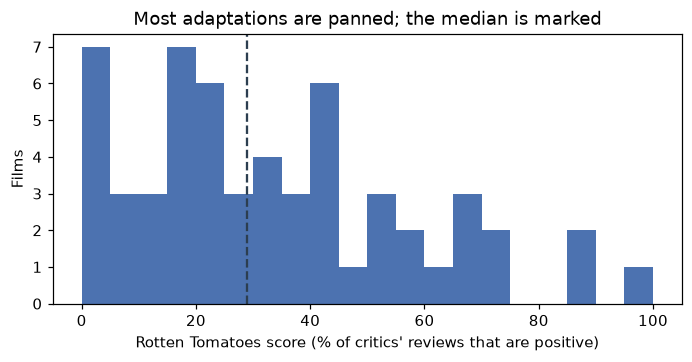

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(sample["rt"], bins=range(0, 105, 5), color="#4C72B0")
ax.axvline(sample["rt"].median(), color="#2c3e50", ls="--", lw=1.5)
ax.set(xlabel="Rotten Tomatoes score (% of critics' reviews that are positive)", ylabel="Films",
       title="Most adaptations are panned; the median is marked")
plt.tight_layout(); plt.show()

*Figure 1. Most video-game adaptations are reviewed badly: the median film (dashed line) has 29% positive reviews, and only 9 of the 57 pass 60%.*

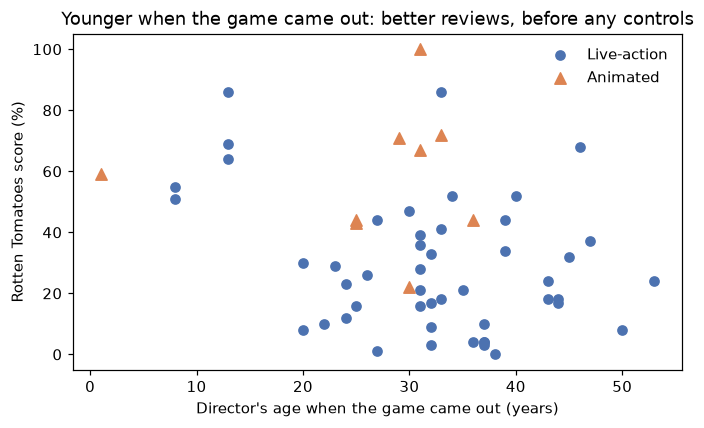

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 4))
live = sample["animated"] == 0
ax.scatter(sample.loc[live, "age_game"], sample.loc[live, "rt"], color="#4C72B0", label="Live-action")
ax.scatter(sample.loc[~live, "age_game"], sample.loc[~live, "rt"], color="#DD8452", marker="^", s=55, label="Animated")
ax.set(xlabel="Director's age when the game came out (years)", ylabel="Rotten Tomatoes score (%)",
       title="Younger when the game came out: better reviews, before any controls")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

*Figure 2. Films by directors who were younger when the game came out are rated better, before any controls. Section 3 asks how much of that is the release year.*

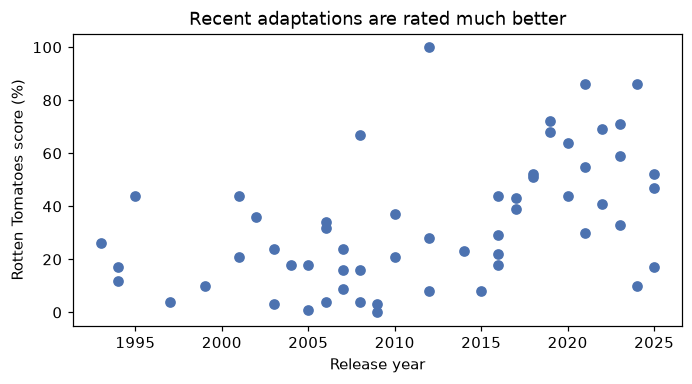

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.scatter(sample["year"], sample["rt"], color="#4C72B0")
ax.set(xlabel="Release year", ylabel="Rotten Tomatoes score (%)", title="Recent adaptations are rated much better")
plt.tight_layout(); plt.show()

*Figure 3. Critics' scores rise with the release year: films released since 2016 average about 48%, against about 20% to 24% before. Year is the variable to hold fixed.*

## Section 3: The Model (25 pts)

In [19]:
with_budget = sample.dropna(subset=["log_budget"])
m1 = smf.ols("rt ~ age_game", sample).fit(cov_type="HC1")
m2 = smf.ols("rt ~ age_game + year + animated", sample).fit(cov_type="HC1")
m2b = smf.ols("rt ~ age_game + year + animated", with_budget).fit(cov_type="HC1")
m3 = smf.ols("rt ~ age_game + year + animated + log_budget", with_budget).fit(cov_type="HC1")

def regtable(models, names):
    rows = {}
    for name, m in zip(names, models):
        col = {}
        for v in ["age_game", "dir_age", "lag", "year", "animated", "log_budget", "Intercept"]:
            if v in m.params:
                col[v] = f"{m.params[v]:.2f}"
                col[v + " (se)"] = f"({m.bse[v]:.2f})"
        col["N"], col["R²"] = f"{int(m.nobs)}", f"{m.rsquared:.2f}"
        rows[name] = col
    return pd.DataFrame(rows).fillna("")

regtable([m1, m2, m2b, m3], ["(1) Age only", "(2) Main", "(3) Main, films with a budget", "(4) Adds budget"])

,(1) Age only,(2) Main,"(3) Main, films with a budget",(4) Adds budget
age_game,-0.72,-0.30,-0.36,-0.37
age_game (se),(0.23),(0.25),(0.24),(0.23)
Intercept,55.91,-2138.94,-2218.45,-2207.50
Intercept (se),(7.80),(603.99),(629.15),(645.64)
N,57,57,53,53
R²,0.10,0.40,0.36,0.38
year,,1.08,1.12,1.11
year (se),,(0.30),(0.31),(0.32)
animated,,23.36,12.47,11.10
animated (se),,(8.67),(8.44),(7.71)


In [20]:
b, (lo, hi) = m2.params["age_game"], m2.conf_int().loc["age_game"]
print(f"Main model: one more year of age when the game came out -> {b:+.2f} points (95% CI {lo:+.2f} to {hi:+.2f})")
print(f"Ten years younger -> {-10 * b:+.1f} points (95% CI {-10 * hi:+.1f} to {-10 * lo:+.1f})")
print(f"Each later release year -> {m2.params['year']:+.2f} points; animated -> {m2.params['animated']:+.1f} points")
print(f"Age only, no controls: {m1.params['age_game']:+.2f} points per year (95% CI {m1.conf_int().loc['age_game'][0]:+.2f} to {m1.conf_int().loc['age_game'][1]:+.2f})")
recent = sample["year"] >= 2016
print(f"Age when the game came out, mean: {sample.loc[~recent, 'age_game'].mean():.1f} for films before 2016, {sample.loc[recent, 'age_game'].mean():.1f} from 2016;"
      f" corr(age, year) = {sample['age_game'].corr(sample['year']):.2f}")
r2_no_year = smf.ols("rt ~ age_game + animated", sample).fit().rsquared
print(f"R² without the release year: {r2_no_year:.2f} (main model {m2.rsquared:.2f})")
budget_on_age = smf.ols("log_budget ~ age_game + year + animated", with_budget).fit(cov_type="HC1")
pct = lambda x: 100 * (np.exp(x) - 1)
print(f"Directors who were older when the game came out get bigger budgets: {pct(budget_on_age.params['age_game']):+.1f}% per year")
print(f"Films with a budget: age {m2b.params['age_game']:+.2f} without budget, {m3.params['age_game']:+.2f} with it")

Main model: one more year of age when the game came out -> -0.30 points (95% CI -0.79 to +0.19)
Ten years younger -> +3.0 points (95% CI -1.9 to +7.9)
Each later release year -> +1.08 points; animated -> +23.4 points
Age only, no controls: -0.72 points per year (95% CI -1.17 to -0.27)
Age when the game came out, mean: 34.3 for films before 2016, 26.9 from 2016; corr(age, year) = -0.29
R² without the release year: 0.25 (main model 0.40)
Directors who were older when the game came out get bigger budgets: +0.2% per year
Films with a budget: age -0.36 without budget, -0.37 with it


**Roles of the controls.** *Release year* is a confounder, and here it does real work: critics' scores rose sharply over three
decades (Figure 3), and recent films adapt games that came out when their directors were young. Holding the year
fixed shrinks the age coefficient from column 1 to column 2. *Animated* is a
confounder: animated adaptations are made by different directors and reviewed on a different curve. *Budget* is left
out of the main model: directors who were older when the game came out get bigger budgets, and a budget can change how good a film is, so budget
sits on the path from age to the score (a mediator, Topic 10). Columns 3 and 4 compare the same films with and
without it. *Number of reviews* is not a control either: it depends on how big and talked-about the film became.

## Section 4: Diagnostics (20 pts)

Breusch-Pagan p = 0.33
VIF: {'age_game': np.float64(1.12), 'year': np.float64(1.11), 'animated': np.float64(1.04)}
Largest Cook's distance:
title
Resident Evil: Damnation    0.211
Ratchet & Clank             0.125
Sonic the Hedgehog 3        0.110


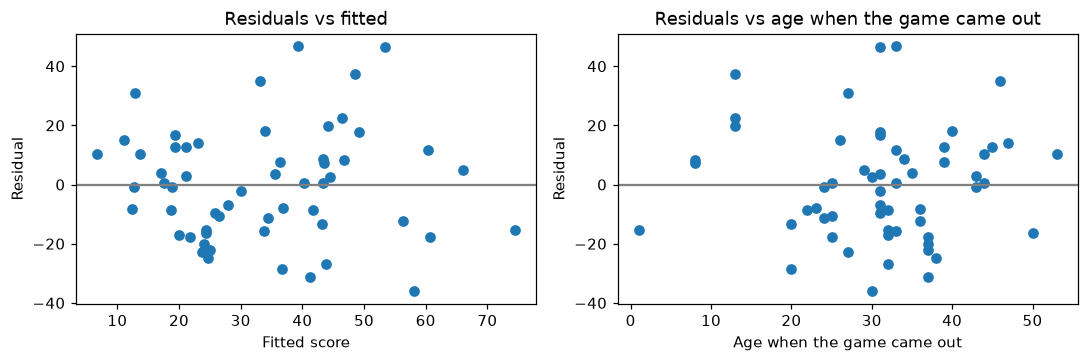

In [21]:
ols2 = smf.ols("rt ~ age_game + year + animated", sample).fit()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(ols2.fittedvalues, ols2.resid); ax[0].axhline(0, color="grey")
ax[0].set(xlabel="Fitted score", ylabel="Residual", title="Residuals vs fitted")
ax[1].scatter(sample["age_game"], ols2.resid); ax[1].axhline(0, color="grey")
ax[1].set(xlabel="Age when the game came out", ylabel="Residual", title="Residuals vs age when the game came out")
plt.tight_layout(); plt.show()

bp_p = het_breuschpagan(ols2.resid, ols2.model.exog)[1]
print(f"Breusch-Pagan p = {bp_p:.2f}")
X = ols2.model.exog
print("VIF:", {n: round(variance_inflation_factor(X, i), 2) for i, n in enumerate(ols2.model.exog_names) if n != "Intercept"})
cooks = pd.Series(ols2.get_influence().cooks_distance[0], index=sample["title"])
print("Largest Cook's distance:"); print(cooks.nlargest(3).round(3).to_string())

In [22]:
# A score from a handful of reviews is noisy. Report the estimate without films that have fewer than 20.
few = sample["reviews"] < 20
m2_many = smf.ols("rt ~ age_game + year + animated", sample[~few]).fit(cov_type="HC1")
print(f"Without the {few.sum()} films with under 20 reviews: age {m2_many.params['age_game']:+.2f} points "
      f"(se {m2_many.bse['age_game']:.2f}), N = {int(m2_many.nobs)}")
# The median instead of the mean: a median regression on the same model.
q = smf.quantreg("rt ~ age_game + year + animated", sample).fit(q=0.5)
qlo, qhi = q.conf_int().loc["age_game"]
print(f"Median regression: age {q.params['age_game']:+.2f} points (95% CI {qlo:+.2f} to {qhi:+.2f})")
# The cruder X: the director's age at release, the first version of this question.
m_rel = smf.ols("rt ~ dir_age + year + animated", sample).fit(cov_type="HC1")
print(f"With age at release instead: {m_rel.params['dir_age']:+.2f} points per year (95% CI {m_rel.conf_int().loc['dir_age'][0]:+.2f} to {m_rel.conf_int().loc['dir_age'][1]:+.2f})")
# X splits into two parts: age at release, and how long the game had been out (X = age at release - lag).
sample["lag"] = sample["year"] - sample["game_year"]
m5 = smf.ols("rt ~ dir_age + lag + year + animated", sample).fit(cov_type="HC1")
print(f"Split: age at release {m5.params['dir_age']:+.2f} (95% CI {m5.conf_int().loc['dir_age'][0]:+.2f} to {m5.conf_int().loc['dir_age'][1]:+.2f}), "
      f"years the game had been out {m5.params['lag']:+.2f} (95% CI {m5.conf_int().loc['lag'][0]:+.2f} to {m5.conf_int().loc['lag'][1]:+.2f})")
# A cut I did not plan: under 20 when the game came out. Shown only as what a tempting subgroup looks like (Section 5).
sample["grew_up"] = (sample["age_game"] < 20).astype(int)
m_gu = smf.ols("rt ~ grew_up + year + animated", sample).fit(cov_type="HC1")
print(f"Under 20 when the game came out ({sample['grew_up'].sum()} films): {m_gu.params['grew_up']:+.1f} points "
      f"(95% CI {m_gu.conf_int().loc['grew_up'][0]:+.1f} to {m_gu.conf_int().loc['grew_up'][1]:+.1f})")

Without the 6 films with under 20 reviews: age -0.34 points (se 0.25), N = 51
Median regression: age -0.22 points (95% CI -0.98 to +0.54)
With age at release instead: -0.25 points per year (95% CI -0.86 to +0.37)
Split: age at release -0.28 (95% CI -0.89 to +0.33), years the game had been out +0.33 (95% CI -0.50 to +1.15)
Under 20 when the game came out (6 films): +24.5 points (95% CI +8.8 to +40.2)


## Section 5: Threats and Conclusion (10 pts)

Age when the game came out is still a stand-in for what the hypothesis is about, whether the director played it: a
director of 12 may never have owned a console, and one of 35 may have played it every night. The "based on" page also
decides the date: the 2018 *Tomb Raider* is based on the 2013 reboot, not the 1996 original. The franchise problem
remains too: studios hand later films in a series to directors they trust. So the estimate is a **conditional
association**, not the effect of having grown up with the game. With another month: code each director's own gaming
history from interviews, weight each score by its review count, and add a franchise flag.

## Numbers my report quotes

In [23]:
REPORT_NUMBERS = {
    "Line 1: rows read": len(raw),
    "Line 2: repeated titles": int(films["title"].duplicated().sum()),
    "Line 3: missing budgets": int(films["budget"].isna().sum()),
    "Line 3: missing RT scores": int(films["rt"].isna().sum()),
    "Line 4: naive merge unmatched": int((naive["_merge"] == "left_only").sum()),
    "Line 4: fixed merge unmatched": int((df["first_director"].isin(directors["director"]) == False).sum()),
    "Line 4: no birth date after the fix": born_missing_first,
    "Line 3: second search, found": int(len(found)),
    "Line 3: second search, not found": int(search["value"].isna().sum()),
    "Line 3: second search, birth dates found": int((found["field"] == "born").sum()),
    "Line 3: birth dates still missing": int(df["born"].isna().sum()),
    "Section 1: films in sample": len(sample),
    "Section 1: RT mean": round(sample["rt"].mean(), 1),
    "Section 1: RT median": round(sample["rt"].median(), 1),
    "Section 1: skew of RT": round(sample["rt"].skew(), 2),
    "Section 3: age, points per year (main)": round(b, 2),
    "Section 3: age CI low": round(lo, 2),
    "Section 3: age CI high": round(hi, 2),
    "Section 3: ten years younger, points": round(-10 * b, 1),
    "Section 3: age, points per year (age only)": round(m1.params["age_game"], 2),
    "Section 3: age only CI low": round(m1.conf_int().loc["age_game"][0], 2),
    "Section 3: age only CI high": round(m1.conf_int().loc["age_game"][1], 2),
    "Section 3: year, points per year": round(m2.params["year"], 2),
    "Section 3: animated, points": round(m2.params["animated"], 1),
    "Section 3: R2 main": round(m2.rsquared, 2),
    "Section 3: R2 without year": round(r2_no_year, 2),
    "Section 3: age at game, films before 2016": round(sample.loc[~recent, "age_game"].mean(), 1),
    "Section 3: age at game, films from 2016": round(sample.loc[recent, "age_game"].mean(), 1),
    "Section 3: corr(age, year)": round(sample["age_game"].corr(sample["year"]), 2),
    "Section 3: films with a budget": int(m2b.nobs),
    "Section 3: age on budget films, without budget": round(m2b.params["age_game"], 2),
    "Section 3: age on budget films, with budget": round(m3.params["age_game"], 2),
    "Section 3: budget, % per year of age": round(pct(budget_on_age.params["age_game"]), 1),
    "Section 4: Breusch-Pagan p": round(bp_p, 2),
    "Section 4: max VIF": round(max(variance_inflation_factor(X, i) for i in range(1, X.shape[1])), 2),
    "Section 4: top Cook's film": cooks.idxmax(),
    "Section 4: films with under 20 reviews": int(few.sum()),
    "Section 4: age without them": round(m2_many.params["age_game"], 2),
    "Section 4: median regression age": round(q.params["age_game"], 2),
    "Section 4: age at release instead": round(m_rel.params["dir_age"], 2),
    "Section 4: mean game age at adaptation": round(sample["lag"].mean(), 1),
    "Section 4: split, age at release": round(m5.params["dir_age"], 2),
    "Section 4: split, game age": round(m5.params["lag"], 2),
    "Section 4: under 20 films": int(sample["grew_up"].sum()),
    "Section 4: under 20 points": round(m_gu.params["grew_up"], 1),
    "Section 2: game years found": int(df["game_year"].notna().sum()),
}
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Line 1: rows read: 68
Line 2: repeated titles: 3
Line 3: missing budgets: 7
Line 3: missing RT scores: 4
Line 4: naive merge unmatched: 10
Line 4: fixed merge unmatched: 6
Line 4: no birth date after the fix: 8
Line 3: second search, found: 7
Line 3: second search, not found: 9
Line 3: second search, birth dates found: 5
Line 3: birth dates still missing: 3
Section 1: films in sample: 57
Section 1: RT mean: 33.6
Section 1: RT median: 29.0
Section 1: skew of RT: 0.72
Section 3: age, points per year (main): -0.3
Section 3: age CI low: -0.79
Section 3: age CI high: 0.19
Section 3: ten years younger, points: 3.0
Section 3: age, points per year (age only): -0.72
Section 3: age only CI low: -1.17
Section 3: age only CI high: -0.27
Section 3: year, points per year: 1.08
Section 3: animated, points: 23.4
Section 3: R2 main: 0.4
Section 3: R2 without year: 0.25
Section 3: age at game, films before 2016: 34.3
Section 3: age at game, films from 2016: 26.9
Section 3: corr(age, year): -0.29
Section

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.